# Proyek Analisis Data: [Bike Sharing Dataset]
- **Nama:** [Anugerah Fadhil Rachman]
- **Email:** [anugerahfadhil5@gmail.com]
- **ID Dicoding:** [anfarn]

## Menentukan Pertanyaan Bisnis

**SMART Question** adalah sebuah framework untuk merumuskan pertanyaan secara terstruktur agar memeperoleh informasi yang mendalam.

* **Spesific (Spesifik)**
  * Pertanyaan harus jelas, fokus pada sebuah topik tertentu, dan tidak bermakna ganda. Hindari pertanyaan yang terlalu luas.
    * Salah: Bagaimana cara meningkatkan penjualan?
    * Benar: Faktor apa saja yang memengaruhi penurunan penjualan produk kategori elektronik di wilayah Jakarta selama kuartal terakhir?
* **Measurable (Terukur)**
  * Pertanyaan harus bisa dijawab dengan angka atau matrix yang konkret, harus tahu apa yang akan dihitung.
    * Salah: Apakah pelanggan senang dengan layanan kita?
    * Benar: Berapa skor rata-rata Customer Satisfaction untuk layanan purna jual bulan ini dibandingkan bulan lalu?
* **Action-Oriented (Berorientasi Aksi)**
  * Hasil dari pertanyaan harus bisa memberikan arahan untuk melakukan tindakan nyata. Jika pertanyaan terjawab, stakeholder harus tahu apa langkah selanjutnya.
    * Salah: Mengapa orang suka berbelanja?
    * Benar: Fitur apa pada aplikasi yang paling sering digunakan sebelum pengguna memutuskan untuk melakukan checkout?
* **Relevant (Relevan)**
  * Hasil dari pertanyaan harus sejalan dengan tujuan utama bisnis atau masalah yang sedang dihadapi.
    * Salah: Menanyakan tentang stok gudang saat masalah utamanya adalah efektivitas kampanye media sosial.
    * Benar: Apakah kampanye iklan di Instagram memberikan Return on Ad Spend (ROAS) yang lebih tinggi dibandingkan iklan di TikTok?
* **Time-bound (Terikat Waktu)**
  * Pertanyaan harus ada batasan waktu yang jelas agar analisis memiliki konteks yang tepat.
    * Salah: Berapa banyak pengguna baru kita?
    * Benar: Berapa tingkat pertumbuhan pengguna baru secara bulanan (Month-over-Month) sepanjang tahun 2025?

**Contoh pertanyaan bisnis yang memenuhi seluruh elemen SMART**

***"Faktor apa saja yang memengaruhi penurunan conversion rate pada pengguna aplikasi Android di wilayah Jabodetabek sebesar 5% selama periode Flash Sale Maret 2026?"***

Keterangan:

- **Specific**: Fokus pada "penurunan conversion rate" untuk "aplikasi Android" di "Jabodetabek". Bukan sekadar penjualan turun.
- **Measurable**: Ada angka konkret yang ingin dianalisis, yaitu penurunan sebesar "5%".
- **Action-Oriented**: Dengan mengetahui faktor penyebabnya misalnya bug pada versi Android tertentu atau kendala logistik di Jabodetabek, tim bisa langsung melakukan perbaikan teknis atau operasional.
- **Relevant**: Penurunan konversi saat Flash Sale adalah masalah kritis bagi bisnis retail/e-commerce.
- **Time-bound**: Dibatasi pada periode spesifik "Flash Sale Maret 2026".

- **Pertanyaan 1:** Bagaimana tren rata-rata jumlah penyewaan sepeda (cnt) pada berbagai kondisi cuaca (weathersit) secara harian selama tahun 2011-2012?
- **Pertanyaan 2:** Apakah terdapat perbedaan pola penyewaan sepeda per jam (hr) antara hari kerja (workingday) dan hari libur/akhir pekan?

## Import Semua Packages/Library yang Digunakan

In [13]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import datetime as dt

## Data Wrangling

### Gathering Data

#### Load df ...

In [14]:
# Memuat dataset
day_df = pd.read_csv("day.csv")
hour_df = pd.read_csv("hour.csv")

# Menampilkan cuplikan data
display(day_df.head())
display(hour_df.head())

,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600


,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


**Insight:** (Opsional)
- Dataset day_df memuat 731 baris dan 16 kolom yang mencatat agregasi penyewaan harian.
- Dataset hour_df memuat 17.379 baris dan 17 kolom yang mencatat agregasi penyewaan per jam.
- Kedua dataset memiliki variabel lengkap mengenai informasi waktu, kondisi cuaca, serta pemisahan tipe pengguna (casual dan registered).

### Assessing Data

#### Identifying ... problem

In [15]:
# 1. Memeriksa tipe data
print("Info day_df:")
day_df.info()

print("\nInfo hour_df:")
hour_df.info()

# 2. Memeriksa missing values dan duplikasi
print("\nMissing values day_df:\n", day_df.isna().sum().sum())
print("Duplikasi day_df:", day_df.duplicated().sum())

print("\nMissing values hour_df:\n", hour_df.isna().sum().sum())
print("Duplikasi hour_df:", hour_df.duplicated().sum())

Info day_df:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     731 non-null    int64  
 1   dteday      731 non-null    object 
 2   season      731 non-null    int64  
 3   yr          731 non-null    int64  
 4   mnth        731 non-null    int64  
 5   holiday     731 non-null    int64  
 6   weekday     731 non-null    int64  
 7   workingday  731 non-null    int64  
 8   weathersit  731 non-null    int64  
 9   temp        731 non-null    float64
 10  atemp       731 non-null    float64
 11  hum         731 non-null    float64
 12  windspeed   731 non-null    float64
 13  casual      731 non-null    int64  
 14  registered  731 non-null    int64  
 15  cnt         731 non-null    int64  
dtypes: float64(4), int64(11), object(1)
memory usage: 91.5+ KB

Info hour_df:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17379 entries, 

**Steps to Take:**
- Mengubah tipe data kolom `dteday` ke tipe data `datetime`.
- Melakukan mapping (pemberian label string) pada kolom `weathersit` dan `workingday` untuk kemudahan visualisasi dan interpretasi EDA.

**Insight:** (Opsional)
- Tidak ditemukan nilai hilang (missing value) maupun data duplikat pada kedua dataset.
- Kolom dteday masih ber tipe data string/object, sehingga perlu dikonversi ke datetime.
- Nilai numerik pada variabel kategorikal seperti weathersit dan workingday memerlukan pemetaan (mapping) ke label deskriptif agar analisis lebih intuitif.

### Cleaning Data

#### Fixing ... problem

In [16]:
# 1. Mengubah tipe data dteday menjadi datetime
day_df['dteday'] = pd.to_datetime(day_df['dteday'])
hour_df['dteday'] = pd.to_datetime(hour_df['dteday'])

# 2. Mapping label untuk weathersit
weather_map = {
    1: 'Clear/Partly Cloudy',
    2: 'Mist/Cloudy',
    3: 'Light Snow/Rain',
    4: 'Severe Weather'
}
day_df['weathersit_desc'] = day_df['weathersit'].map(weather_map)
hour_df['weathersit_desc'] = hour_df['weathersit'].map(weather_map)

# 3. Mapping label untuk workingday
workday_map = {
    0: 'Weekend/Holiday',
    1: 'Working Day'
}
hour_df['workingday_desc'] = hour_df['workingday'].map(workday_map)

print("Tipe data dteday sekarang:", day_df['dteday'].dtypes)

hour_df.to_csv("main_data.csv", index=False)

Tipe data dteday sekarang: datetime64[ns]


**Insight:** (Opsional)
- Tipe data kolom dteday telah diperbarui menjadi datetime64 untuk mempermudah manipulasi berbasis waktu.
- Kolom baru weathersit_desc dan workingday_desc berhasil dibuat untuk menggantikan kode angka dengan teks kualitatif.
- Seluruh data kini berada dalam kondisi bersih dan siap untuk tahap eksplorasi (EDA).

## Exploratory Data Analysis (EDA)

### Explore ...

In [17]:
# Eksplorasi penyewaan berdasarkan kondisi cuaca (Harian)
weather_rentals = day_df.groupby(by='weathersit_desc').agg({
    'cnt': ['mean', 'max', 'min']
}).reset_index()
print("Statistik penyewaan harian berdasarkan cuaca:")
display(weather_rentals)

# Eksplorasi pola penyewaan per jam antara hari kerja dan libur
hourly_rentals = hour_df.groupby(by=['workingday_desc', 'hr']).agg({
    'cnt': 'mean'
}).reset_index()
print("\nCuplikan rata-rata penyewaan per jam:")
display(hourly_rentals.head(10))

Statistik penyewaan harian berdasarkan cuaca:


weathersit_desc          cnt           
                               mean   max  min
0  Clear/Partly Cloudy  4876.786177  8714  431
1      Light Snow/Rain  1803.285714  4639   22
2          Mist/Cloudy  4035.862348  8362  605


Cuplikan rata-rata penyewaan per jam:


,workingday_desc,hr,cnt
0,Weekend/Holiday,0,90.800000
1,Weekend/Holiday,1,69.508696
2,Weekend/Holiday,2,53.171053
3,Weekend/Holiday,3,25.775330
4,Weekend/Holiday,4,8.264317
5,Weekend/Holiday,5,8.689189
6,Weekend/Holiday,6,18.742358
7,Weekend/Holiday,7,43.406926
8,Weekend/Holiday,8,105.653680
9,Weekend/Holiday,9,171.623377


**Insight:** (Opsional)
- Penyewaan harian tertinggi terjadi pada cuaca cerah/berawan dengan rata-rata 4.877 sewa, lalu merosot hingga 1.803 sewa saat terjadi hujan/salju ringan.
- Pada hari kerja (working day), puncak penyewaan terjadi pada pukul 08:00 (rata-rata 477 sewa) serta pukul 17:00–18:00 (rata-rata >490 sewa).
- Pada hari libur/akhir pekan, tren penyewaan cenderung stabil di siang hingga sore hari (pukul 12:00–16:00) pada kisaran 350–372 sewa per jam.

## Visualization & Explanatory Analysis

### Pertanyaan 1: Bagaimana tren rata-rata jumlah penyewaan sepeda berdasarkan kondisi cuaca?

/tmp/ipykernel_2080/2086604066.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


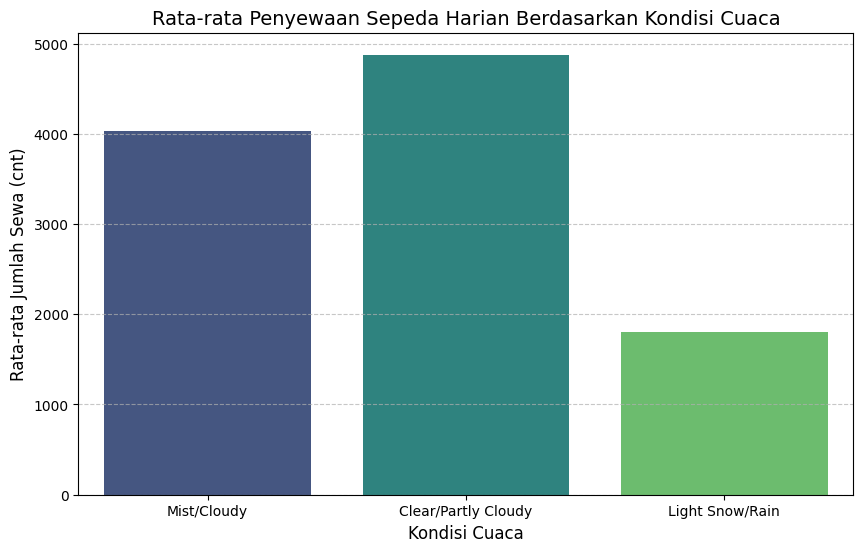

In [18]:
plt.figure(figsize=(10, 6))
sns.barplot(
    x='weathersit_desc',
    y='cnt',
    data=day_df,
    estimator='mean',
    palette='viridis',
    errorbar=None
)
plt.title('Rata-rata Penyewaan Sepeda Harian Berdasarkan Kondisi Cuaca', fontsize=14)
plt.xlabel('Kondisi Cuaca', fontsize=12)
plt.ylabel('Rata-rata Jumlah Sewa (cnt)', fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

### Pertanyaan 2: Bagaimana perbedaan pola penyewaan sepeda per jam (hr) antara hari kerja dan akhir pekan?

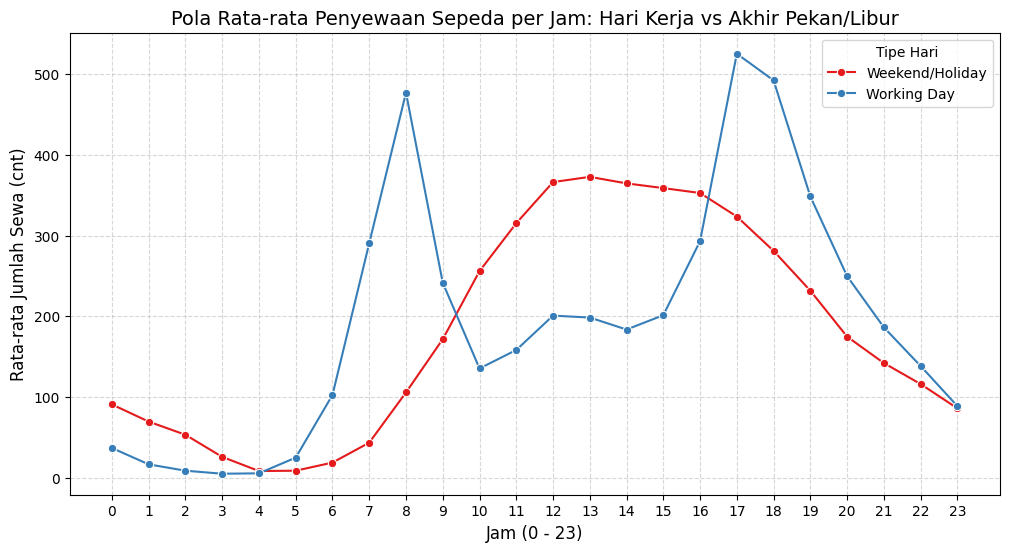

In [19]:
plt.figure(figsize=(12, 6))
sns.lineplot(
    x='hr',
    y='cnt',
    hue='workingday_desc',
    data=hourly_rentals,
    marker='o',
    palette='Set1'
)
plt.title('Pola Rata-rata Penyewaan Sepeda per Jam: Hari Kerja vs Akhir Pekan/Libur', fontsize=14)
plt.xlabel('Jam (0 - 23)', fontsize=12)
plt.ylabel('Rata-rata Jumlah Sewa (cnt)', fontsize=12)
plt.xticks(range(0, 24))
plt.legend(title='Tipe Hari')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

**Insight:** (Opsional)
- Kondisi cuaca berkorelasi positif dengan volume sewa, di mana cuaca buruk menurunkan total sewa hingga lebih dari 60% dibanding kondisi cerah.
- Grafik waktu memperlihatkan dua segmen profil pengguna yang jelas: kelompok commuter (mobilitas kerja) pada hari kerja dan kelompok recreational (rekreasi) pada akhir pekan.

## Analisis Lanjutan (Opsional)

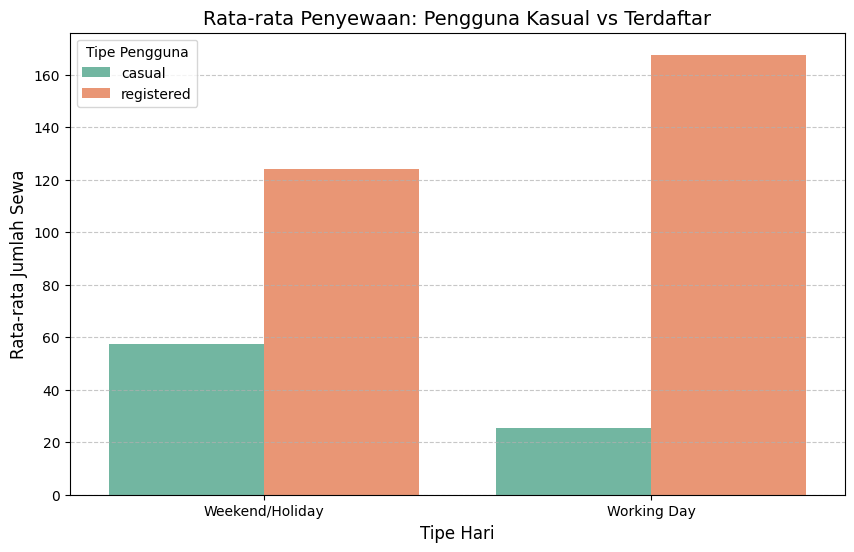

5 Jam dengan rata-rata penyewaan terendah (Rekomendasi waktu perawatan):


,hr,cnt
4,4,6.352941
3,3,11.727403
5,5,19.889819
2,2,22.869930
1,1,33.375691


In [20]:
# 1. Analisis Perbandingan Pengguna (Casual vs Registered) pada Hari Kerja vs Libur
user_type_df = hour_df.groupby('workingday_desc')[['casual', 'registered']].mean().reset_index()

# Mengubah bentuk tabel (melt) agar mudah divisualisasikan dengan Seaborn
user_type_melted = user_type_df.melt(
    id_vars='workingday_desc',
    value_vars=['casual', 'registered'],
    var_name='user_type',
    value_name='avg_rentals'
)

plt.figure(figsize=(10, 6))
sns.barplot(
    x='workingday_desc',
    y='avg_rentals',
    hue='user_type',
    data=user_type_melted,
    palette='Set2'
)
plt.title('Rata-rata Penyewaan: Pengguna Kasual vs Terdaftar', fontsize=14)
plt.xlabel('Tipe Hari', fontsize=12)
plt.ylabel('Rata-rata Jumlah Sewa', fontsize=12)
plt.legend(title='Tipe Pengguna')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

# 2. Menemukan jam dengan rata-rata penyewaan terendah untuk jadwal perawatan
lowest_hours = hour_df.groupby('hr')['cnt'].mean().reset_index()
lowest_hours = lowest_hours.sort_values(by='cnt').head(5) # Mengambil 5 jam terendah

print("5 Jam dengan rata-rata penyewaan terendah (Rekomendasi waktu perawatan):")
display(lowest_hours)

**Insight:** (Opsional)
- Pengguna terdaftar (registered) mendominasi total transaksi pada jam kerja, sedangkan pengguna kasual (casual) meningkat signifikan pada akhir pekan.
- Jam operasional rendah pemakaian (pukul 01:00–04:00) merupakan waktu paling ideal untuk melakukan perawatan rutin dan redistribusi unit sepeda.

## Conclusion & Recommendation

- **Conclusion pertanyaan 1:** Kondisi cuaca sangat memengaruhi jumlah penyewaan sepeda. Cuaca cerah (Clear/Partly Cloudy) menghasilkan rata-rata penyewaan tertinggi. Sebaliknya, cuaca buruk (Light Snow/Rain atau Severe Weather) secara drastis menurunkan minat penyewaan.
- **Conclusion pertanyaan 2:** Terdapat perbedaan pola yang sangat jelas. Pada hari kerja (*Working Day*), penyewaan memuncak pada jam sibuk berangkat kerja (08:00) dan pulang kerja (17:00 - 18:00). Pada akhir pekan/hari libur (*Weekend/Holiday*), pola penyewaan lebih landai namun stabil dari siang hingga sore hari (12:00 - 16:00) yang mengindikasikan penggunaan untuk rekreasi.

**Rekomendasi Action Item:**
- **Manajemen Ketersediaan Sepeda:** Distribusikan lebih banyak armada sepeda di stasiun yang dekat dengan area pemukiman/perkantoran tepat sebelum pukul 08:00 pagi dan 17:00 sore pada hari kerja. Pada akhir pekan, pastikan ketersediaan penuh di area rekreasi dan taman pada siang hari.
- **Strategi Promosi Cuaca:** Karena cuaca mendung/gerimis (Mist/Light Rain) menurunkan konversi sewa, tim marketing dapat memberikan promo diskon otomatis di aplikasi saat cuaca kurang mendukung untuk tetap memancing minat penyewa jarak dekat.